# 04 · Exploration du jeu nettoyé : ce que le machine learning doit savoir

**Objectif** : comprendre les régularités et les pièges du jeu final **pour décider** : quelles variables (features) créer, quel découpage train/test, quelles baselines, un modèle par bâtiment ou global.

Chaque section suit le même schéma : **Question → Graphique → Observation → Conséquence pour le ML**.

> Rappel : ce notebook *observe*. Aucun seuil de nettoyage n'est modifié ici en regardant 2017 ; s'il faut changer une règle, on retourne au notebook 03 et on le note dans le journal.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..")                       # ce notebook s'exécute depuis notebooks/
RAW = ROOT / "data" / "raw" / "bdg2"    # fichiers téléchargés (jamais modifiés, jamais dans Git)
INTERIM = ROOT / "data" / "interim"     # résultats intermédiaires (hors Git)
PROCESSED = ROOT / "data" / "processed" # jeu final (hors Git, DVC en S7)
for dossier in (INTERIM, PROCESSED):
    dossier.mkdir(parents=True, exist_ok=True)

SEED = 42
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
df = pd.read_parquet(PROCESSED / "bdg2_elec_clean.parquet")
df["annee"] = df["timestamp"].dt.year
df["mois"] = df["timestamp"].dt.month
df["jour_sem"] = df["timestamp"].dt.dayofweek       # 0 = lundi
df["heure"] = df["timestamp"].dt.hour
df["kwh_m2"] = df["kwh"] / df["sqm"]                # consommation rapportée à la surface : comparable entre bâtiments
valides = df["kwh"].notna() & ~df["kwh_imputed"]    # lignes évaluables
print(f"{len(df):,} lignes, {df['building_id'].nunique()} bâtiments, {valides.mean()*100:.1f} % de lignes évaluables")
df.dtypes

350,880 lignes, 20 bâtiments, 99.8 % de lignes évaluables


timestamp            datetime64[us]
building_id                     str
kwh                         float64
kwh_imputed                    bool
kwh_raw                     float64
site_id                         str
primaryspaceusage               str
sqm                         float64
airTemperature              float64
cloudCoverage               float64
dewTemperature              float64
precipDepth1HR              float64
seaLvlPressure              float64
windDirection               float64
windSpeed                   float64
annee                         int32
mois                          int32
jour_sem                      int32
heure                         int32
kwh_m2                      float64
dtype: object

## 1. Combien consomment les bâtiments, et sont-ils comparables ?

*Question* : un modèle unique peut-il servir à tous, ou faut-il un modèle par bâtiment ?

,count,mean,std,min,25%,50%,75%,max
primaryspaceusage,,,,,,,,
Education,7.00,0.02,0.01,0.01,0.01,0.02,0.02,0.03
Entertainment/public assembly,3.00,0.01,0.01,0.01,0.01,0.02,0.02,0.02
Lodging/residential,3.00,0.01,0.00,0.01,0.01,0.01,0.01,0.01
Office,5.00,0.01,0.00,0.01,0.01,0.01,0.01,0.01
Public services,2.00,0.01,0.01,0.01,0.01,0.01,0.01,0.01


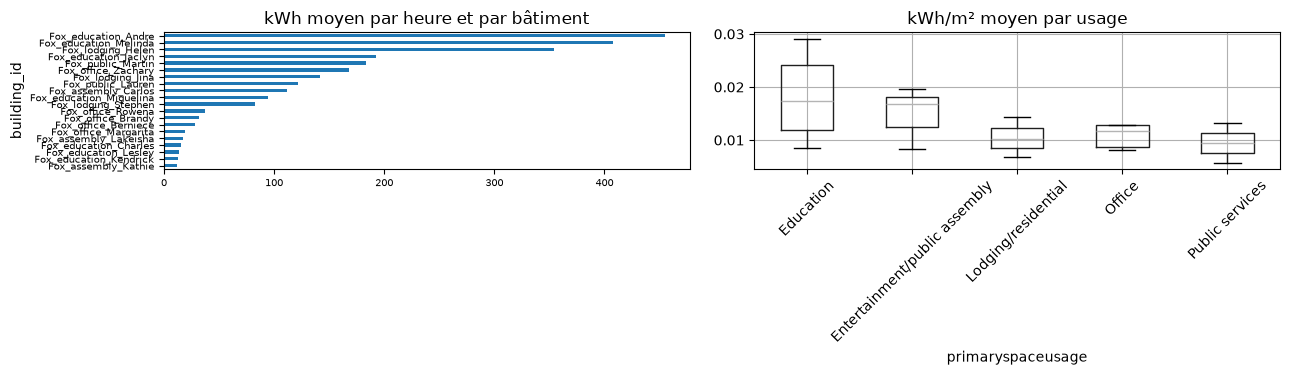

In [3]:
par_bat = df[valides].groupby(["building_id", "primaryspaceusage"]).agg(kwh_moyen=("kwh", "mean"), kwh_m2=("kwh_m2", "mean"), sqm=("sqm", "first")).reset_index()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
par_bat.sort_values("kwh_moyen").set_index("building_id")["kwh_moyen"].plot.barh(ax=ax[0], title="kWh moyen par heure et par bâtiment", fontsize=7)
par_bat.boxplot(column="kwh_m2", by="primaryspaceusage", ax=ax[1], rot=45); ax[1].set_title("kWh/m² moyen par usage"); plt.suptitle("")
plt.tight_layout()
par_bat.groupby("primaryspaceusage")["kwh_m2"].describe()

**Observation** : les 20 bâtiments ont des surfaces très différentes (898 à 51 395 m²) mais des consommations par m² du même ordre (0,01 à 0,03 kWh/m² par heure) ; Education est le plus intense (moyenne 0,02, jusqu'à 0,03). En kWh total, Education pèse 47,6 % et Lodging 23,1 %.   **Conséquence ML** : la MAE en kWh n'est pas comparable entre bâtiments et sera dominée par les plus grands : prévoir en plus une MAE en % de la consommation moyenne ; la surface et l'usage servent de variables à un modèle global ; comparer « un modèle par bâtiment » et « un modèle global ».

## 2. Rythmes : jour, semaine, saison

*Question* : quels cycles la consommation suit-elle ? Ils justifient les **variables de calendrier** et les **retards** (même heure la veille = 24 h, même heure la semaine passée = 168 h).

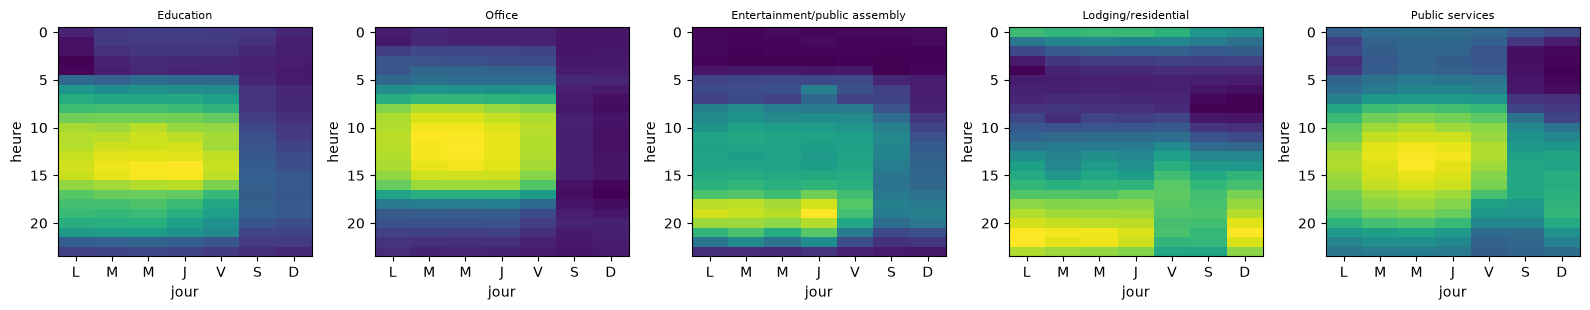

In [4]:
usages = df["primaryspaceusage"].value_counts().index.tolist()
fig, axes = plt.subplots(1, len(usages), figsize=(3.2 * len(usages), 3.2), sharey=False)
for ax, u in zip(np.atleast_1d(axes), usages):
    p = df[valides & (df["primaryspaceusage"] == u)].pivot_table(index="heure", columns="jour_sem", values="kwh_m2", aggfunc="mean")
    ax.imshow(p.values, aspect="auto", cmap="viridis"); ax.set_title(u, fontsize=8)
    ax.set_xticks(range(7)); ax.set_xticklabels(["L", "M", "M", "J", "V", "S", "D"]); ax.set_xlabel("jour"); ax.set_ylabel("heure")
plt.tight_layout()

([<matplotlib.axis.XTick at 0x2111b51ffd0>,
 [Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12')])

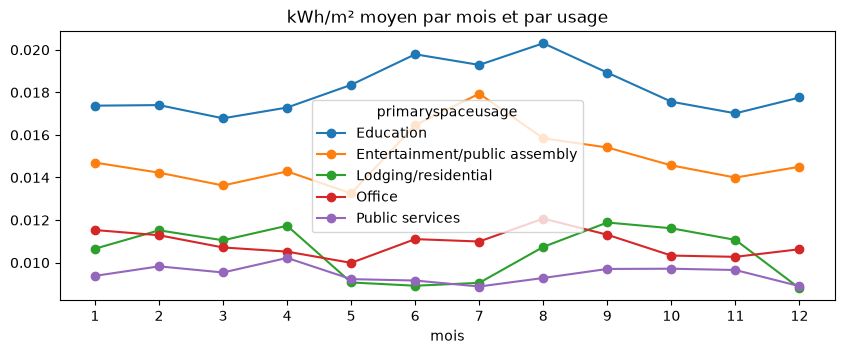

In [5]:
mensuel = df[valides].groupby(["mois", "primaryspaceusage"])["kwh_m2"].mean().unstack()
mensuel.plot(figsize=(10, 3.5), marker="o", title="kWh/m² moyen par mois et par usage"); plt.xticks(range(1, 13))

**Observation** : le profil journalier est marqué (creux nocturne, montée dès 5 h, pic entre 12 h et 15 h). La semaine diffère du week-end surtout pour les bureaux (week-end à 75 % de la semaine) et les salles ouvertes au public (77 %), peu pour Education (91 %) et pas pour Lodging (98 %). La saison compte : Education monte en été (≈ 0,020 kWh/m² de juin à août contre ≈ 0,017 de janvier à avril, effet de la climatisation) alors que Lodging baisse de mai à août (≈ 0,009 contre 0,011 à 0,012 de septembre à novembre), signe du départ des résidents.   **Conséquence ML** : heure, jour de semaine et mois comme variables ; jours fériés du pays du site (États-Unis) et périodes de vacances universitaires comme variables de calendrier ; l'usage (ou le profil) doit être une variable d'un modèle global, car les rythmes diffèrent fortement d'un usage à l'autre.

## 3. Quels retards a-t-on le droit d'utiliser ? (et la consommation « se souvient »-elle ?)

**Règle de base** : à l'instant où la prévision est produite, on ne connaît que le passé. Une prévision « demain heure par heure » produite chaque jour à l'heure **T** ne peut utiliser que des mesures connues à T : utiliser une valeur plus récente serait une **fuite de données**.

Pour l'heure `h` du lendemain, un retard `L` (en heures) est utilisable si `L >= 25 + h - T`.
Exemple avec T = 11 h : « même heure la veille » (L = 24) n'est utilisable que pour les heures 0 à 10 du lendemain, alors que « même heure la semaine passée » (L = 168) l'est toujours.

> **T est une hypothèse de travail** (ici 11 h : fin de matinée, avant que la programmation du lendemain soit arrêtée). Elle sera confirmée ou changée avec le groupe : c'est elle qui fixe les retards autorisés, donc les variables (features) et les baselines.

In [6]:
HEURE_PRODUCTION = 11   # T : hypothèse, à valider en groupe
heures_cibles = np.arange(24)
retards_testes = [24, 48, 72, 168, 336]
dispo = pd.DataFrame({L: L >= 25 + heures_cibles - HEURE_PRODUCTION for L in retards_testes}, index=heures_cibles)
dispo.index.name = "heure du lendemain"
dispo.sum().rename("nb d'heures du lendemain (sur 24) où le retard est utilisable").to_frame()

,nb d'heures du lendemain (sur 24) où le retard est utilisable
24,11
48,24
72,24
168,24
336,24


*Question* : à quel point la valeur d'il y a L heures ressemble-t-elle à la valeur actuelle ? (autocorrélation, par bâtiment). On ne retient que les retards **utilisables** d'après le tableau ci-dessus.

,mean,min,max
1,0.93,0.84,0.97
24,0.77,0.59,0.93
48,0.63,0.27,0.90
168,0.78,0.43,0.93
336,0.73,0.41,0.93


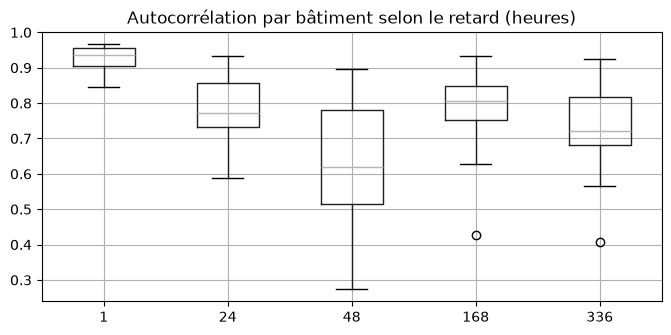

In [7]:
piv = df.pivot(index="timestamp", columns="building_id", values="kwh")
retards = [1, 24, 48, 168, 336]
ac = pd.DataFrame({r: piv.apply(lambda s: s.autocorr(r)) for r in retards})
ac.boxplot(figsize=(8, 3.5)); plt.title("Autocorrélation par bâtiment selon le retard (heures)")
ac.describe().T[["mean", "min", "max"]]

**Observation** : l'autocorrélation moyenne est de 0,93 à 1 h, 0,77 à 24 h, 0,63 à 48 h, **0,78 à 168 h** et 0,73 à 336 h (entre bâtiments : 0,59 à 0,93 à 24 h, 0,27 à 0,90 à 48 h, 0,43 à 0,93 à 168 h). Avec T = 11 h, le retard de 24 h n'est utilisable que pour 11 des 24 heures du lendemain ; 48, 72, 168 et 336 h le sont pour les 24.   **Conséquence ML** : le rythme hebdomadaire (168 h) est aussi informatif que le rythme journalier et toujours utilisable : les baselines B1 (même heure 7 jours avant) et B2 (moyenne des 4 dernières semaines) seront exigeantes ; le retard de 48 h est le plus faible ; variables de retard : 168 h, 336 h, et 24 h seulement pour les heures 0 à 10 du lendemain.

## 3 bis. Quel contexte ces bâtiments racontent-ils ?

Le contexte (campus universitaire, parc de bureaux, collectivité…) ne se décrète pas : il se **déduit** des bâtiments retenus et de leur façon de consommer. On calcule des indicateurs simples par bâtiment, puis par usage.

| Indicateur | Lecture possible (hypothèse à confirmer) |
|---|---|
| `ratio_we_sem` : consommation moyenne le week-end / en semaine | proche de 1 : occupation continue (hébergement, laboratoires) ; faible : bureaux ou enseignement |
| `ratio_nuit_jour` : consommation de 0 h à 5 h / de 9 h à 17 h en semaine | élevé : activité ou équipements 24 h/24 ; faible : bâtiment qui s'éteint la nuit |
| `ratio_noel` : consommation du 24 au 31 décembre / du 8 au 31 janvier | faible : fermeture pendant les fêtes (calendrier d'établissement) |
| `ratio_ete_printemps` : juillet-août / avril-mai | à lire avec le climat : un creux estival suggère un calendrier universitaire, mais la climatisation peut le masquer |

In [8]:
tmp = df[valides].copy()
we, nuit = tmp["jour_sem"] >= 5, tmp["heure"].between(0, 5)
jour = tmp["heure"].between(9, 17) & ~we
mois, jj = tmp["timestamp"].dt.month, tmp["timestamp"].dt.day
noel = (mois == 12) & (jj >= 24)
janvier = (mois == 1) & (jj >= 8)

def moyenne(masque):
    return tmp[masque].groupby("building_id")["kwh"].mean()

ind = pd.DataFrame({
    "ratio_we_sem": moyenne(we) / moyenne(~we),
    "ratio_nuit_jour": moyenne(nuit & ~we) / moyenne(jour),
    "ratio_noel": moyenne(noel) / moyenne(janvier),
    "ratio_ete_printemps": moyenne(mois.isin([7, 8])) / moyenne(mois.isin([4, 5])),
})
ind["usage"] = df.drop_duplicates("building_id").set_index("building_id")["primaryspaceusage"]
part_kwh = (tmp.groupby("primaryspaceusage")["kwh"].sum() / tmp["kwh"].sum() * 100).rename("part_du_kwh_total_%")
part_nb = df.drop_duplicates("building_id")["primaryspaceusage"].value_counts().rename("nb_batiments")
print("Poids de chaque usage dans la consommation du jeu :")
display(pd.concat([part_nb, part_kwh], axis=1).sort_values("part_du_kwh_total_%", ascending=False))
print("Indicateurs médians par usage :")
ind.groupby("usage").median().round(2)

Poids de chaque usage dans la consommation du jeu :


,nb_batiments,part_du_kwh_total_%
primaryspaceusage,,
Education,7,47.63
Lodging/residential,3,23.13
Public services,2,12.23
Office,5,11.35
Entertainment/public assembly,3,5.65


Indicateurs médians par usage :


,ratio_we_sem,ratio_nuit_jour,ratio_noel,ratio_ete_printemps
usage,,,,
Education,0.91,0.69,0.97,1.09
Entertainment/public assembly,0.77,0.53,1.08,1.07
Lodging/residential,0.98,0.97,0.71,0.96
Office,0.75,0.67,0.88,1.19
Public services,0.91,0.83,0.81,0.95


**Observation** : Education porte 47,6 % du kWh (7 bâtiments), Lodging 23,1 % (3), Public services 12,2 % (2), Office 11,4 % (5) et Entertainment 5,7 % (3) : enseignement, hébergement et salles ouvertes au public représentent **76,4 %** du total. Le calendrier d'établissement se voit là où on l'attend : Lodging ne baisse ni le week-end (0,98) ni la nuit (0,97), signe d'une occupation continue, mais chute de **29 %** entre Noël et janvier (0,71) et en été ; les bureaux baissent le week-end (0,75) et de 12 % à Noël (0,88) ; Education varie peu (week-end 0,91, Noël 0,97), avec une grande part de charge de base.

**Règle de décision proposée pour nommer le contexte** (à valider en groupe) :

| Si… | Le contexte est… |
|---|---|
| enseignement + hébergement + équipements ouverts au public portent l'essentiel du kWh **et** un calendrier d'établissement est visible (creux de fin d'année, week-end) | **campus universitaire** |
| les bureaux dominent | **parc de bureaux** |
| les services publics dominent | **collectivité / administrations** |
| mélange sans dominante | **parc de bâtiments tertiaires** |

**Contexte retenu** : **campus universitaire**. **Justification (chiffres)** : 76,4 % du kWh en enseignement, hébergement et équipements ouverts au public ; résidences à occupation continue avec creux de fin d'année (−29 %) et d'été ; sous-usages « College Classroom » (29) et « College Laboratory » (27) parmi les 63 bâtiments d'enseignement du site Fox (`metadata`). À reporter dans l'étude de conception (sections 1 et 2) et dans l'ADR « choix du jeu de données ».

## 4. Rôle de la météo

*Question* : la température explique-t-elle la consommation ? La relation est-elle linéaire ? (si non, une régression linéaire simple sera limitée, un modèle à arbres plus adapté).

In [9]:
sous = df[valides].dropna(subset=["airTemperature", "kwh_m2"])
corr = pd.DataFrame({u: {"spearman": sous.loc[sous["primaryspaceusage"] == u, ["kwh_m2", "airTemperature"]].corr(method="spearman").iloc[0, 1],
                         "pearson": sous.loc[sous["primaryspaceusage"] == u, ["kwh_m2", "airTemperature"]].corr().iloc[0, 1]} for u in usages}).T
corr

,spearman,pearson
Education,0.16,0.16
Office,0.18,0.06
Entertainment/public assembly,0.17,0.22
Lodging/residential,0.01,0.03
Public services,0.10,0.05


Text(0.5, 0, 'température (°C, début de classe)')

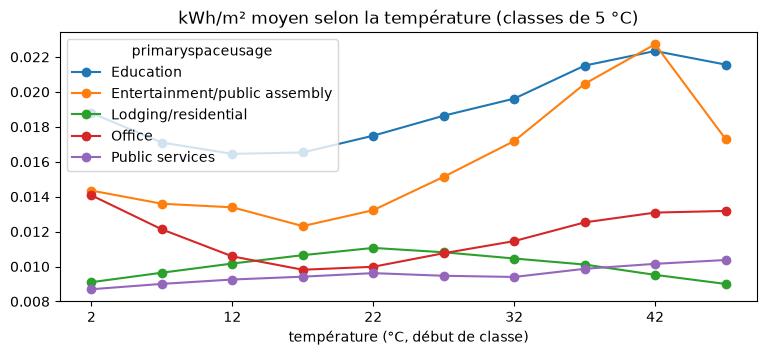

In [10]:
bornes = np.arange(np.floor(sous["airTemperature"].min()), np.ceil(sous["airTemperature"].max()) + 5, 5)
sous = sous.assign(classe_T=pd.cut(sous["airTemperature"], bornes))
courbe = sous.groupby(["classe_T", "primaryspaceusage"], observed=True)["kwh_m2"].mean().unstack()
courbe.index = [f"{int(i.left)}" for i in courbe.index]
courbe.plot(figsize=(9, 3.5), marker="o", title="kWh/m² moyen selon la température (classes de 5 °C)"); plt.xlabel("température (°C, début de classe)")

**Observation** : la corrélation linéaire avec la température est faible (Spearman : Education 0,16, Office 0,18, Entertainment 0,17, Public services 0,10, Lodging 0,01), mais la courbe par classes de 5 °C montre une **forme en U** : pour Office, ≈ 0,014 kWh/m² à 2 °C, ≈ 0,0098 vers 17 °C puis ≈ 0,013 de 42 à 47 °C (chauffage puis climatisation) ; pour Entertainment, ≈ 0,0123 à 22 °C puis ≈ 0,0227 à 42 °C (≈ +85 %) ; pour Education, de ≈ 0,0165 vers 12 à 17 °C à ≈ 0,0224 à 42 °C (≈ +36 %) ; Lodging et Public services sont presque plats (valeurs lues sur le graphique).   **Conséquence ML** : l'effet existe mais n'est pas linéaire : une corrélation faible ne veut pas dire « pas d'effet ». Une régression linéaire sur la température brute sera limitée : il faudra des termes non linéaires (écart à 18 °C, carré, classes) ou un modèle à arbres (LightGBM). La météo du jeu est **mesurée** : en production on aura des **prévisions** (erreur de prévision météo non simulée : limite à écrire en section 9).

## 5. Stabilité entre 2016 et 2017 (risque pour le test)

*Question* : si on entraîne sur 2016 et teste sur 2017, la consommation a-t-elle changé de niveau ? Un décalage (nouveaux bâtiments, travaux, changement de comptage) dégraderait le test sans que le modèle y soit pour quelque chose.

count   20.00
mean     1.03
std      0.14
min      0.80
25%      0.95
50%      1.00
75%      1.07
max      1.33
Name: ratio_2017_2016, dtype: float64

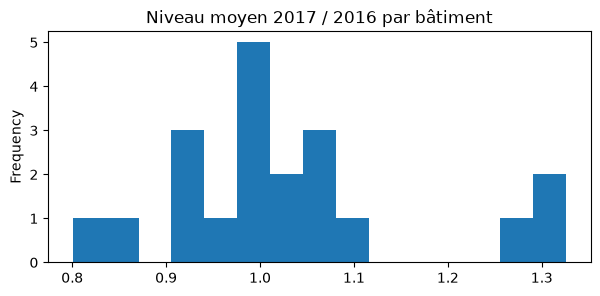

In [11]:
an = df[valides].groupby(["building_id", "annee"])["kwh"].mean().unstack()
an["ratio_2017_2016"] = an[2017] / an[2016]
an["ratio_2017_2016"].plot.hist(bins=15, figsize=(7, 3), title="Niveau moyen 2017 / 2016 par bâtiment")
an["ratio_2017_2016"].describe()

In [12]:
# Bâtiments dont le niveau change fortement (à examiner un par un, pas à supprimer automatiquement)
an[(an["ratio_2017_2016"] < 0.8) | (an["ratio_2017_2016"] > 1.25)]

annee,2016,2017,ratio_2017_2016
building_id,,,
Fox_assembly_Lakeisha,15.19,20.14,1.33
Fox_education_Kendrick,11.00,13.91,1.26
Fox_office_Berniece,24.32,31.46,1.29


**Observation** : le niveau moyen 2017/2016 est stable pour la majorité (médiane 1,00, écart-type 0,14, de 0,80 à 1,33), mais trois bâtiments augmentent de 26 à 33 % en 2017 : `Fox_assembly_Lakeisha` (×1,33), `Fox_office_Berniece` (×1,29) et `Fox_education_Kendrick` (×1,26).   **Conséquence ML** : découpage chronologique proposé : entraînement sur 2016, test sur 2017 (deux années complètes, test réellement futur) ; bâtiments à surveiller : Lakeisha, Berniece et Kendrick (changement de niveau possible : travaux, nouvel usage ou compteur) ; évaluer l'erreur **par bâtiment** pour repérer l'effet de cette dérive.

## 6. Valeurs manquantes résiduelles et lignes évaluables

In [13]:
resume = df.groupby("building_id").agg(pct_nan=("kwh", lambda s: s.isna().mean() * 100), pct_imputes=("kwh_imputed", lambda s: s.mean() * 100))
resume["pct_evaluable"] = 100 - resume["pct_nan"] - resume["pct_imputes"]
resume.sort_values("pct_evaluable").head(8)

,pct_nan,pct_imputes,pct_evaluable
building_id,,,
Fox_assembly_Kathie,0.44,1.28,98.28
Fox_office_Margarita,1.49,0.03,98.48
Fox_assembly_Carlos,0.00,0.24,99.76
Fox_education_Lesley,0.02,0.19,99.79
Fox_office_Rowena,0.07,0.06,99.87
Fox_education_Charles,0.00,0.12,99.88
Fox_office_Berniece,0.09,0.03,99.89
Fox_education_Jaclyn,0.07,0.02,99.91


**Conséquence ML** : [règle commune pour tous les modèles : évaluer sur les mêmes lignes, celles où `kwh` n'est ni NaN ni interpolé ; pour construire les retards, on peut utiliser `kwh` même interpolé, jamais une valeur de la période à prédire].

## 7. (Option data mining) Des familles de bâtiments ?

*Question* : les bâtiments se regroupent-ils par forme de profil journalier (indépendamment de leur taille) ? Si oui, un modèle par famille, ou la famille comme variable, peut être plus pertinent qu'un modèle par bâtiment. Cette cellule demande `scikit-learn` (à ajouter à `requirements.txt` si le groupe la garde).

primaryspaceusage  Education  Entertainment/public assembly  \
famille                                                       
0                          4                              0   
1                          3                              2   
2                          0                              1   

primaryspaceusage  Lodging/residential  Office  Public services  
famille                                                          
0                                    3       3                2  
1                                    0       2                0  
2                                    0       0                0  


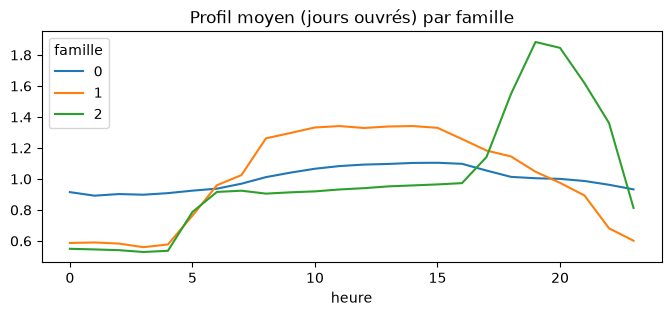

In [14]:
try:
    from sklearn.cluster import KMeans
    profils = (df[valides & (df["jour_sem"] < 5)].groupby(["building_id", "heure"])["kwh"].mean().unstack())
    profils = profils.div(profils.mean(axis=1), axis=0)          # forme du profil, indépendante de la taille
    k = min(3, len(profils))
    familles = pd.Series(KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(profils), index=profils.index, name="famille")
    print(pd.crosstab(familles, df.drop_duplicates("building_id").set_index("building_id").loc[familles.index, "primaryspaceusage"]))
    profils.groupby(familles).mean().T.plot(figsize=(8, 3), title="Profil moyen (jours ouvrés) par famille")
except ImportError:
    print("scikit-learn non installé : cellule facultative, on passe.")

**Observation** : le k-means en 3 familles de profil journalier (jours ouvrés, normalisé par la taille) ne coïncide pas avec l'usage : famille 0 = 12 bâtiments (Education 4, Lodging 3, Office 3, Public services 2), famille 1 = 7 (Education 3, Entertainment 2, Office 2), famille 2 = 1 bâtiment isolé de type Entertainment (probablement une salle d'événements : à vérifier).   **Conséquence ML** : l'usage ne suffit pas à résumer la forme du profil ; avec seulement 20 bâtiments, des familles sont trop fragiles pour un modèle par famille. On garde l'usage comme variable d'un modèle global et on teste en option le profil moyen comme variable supplémentaire ; le bâtiment isolé est à regarder à part (pics d'événements, voir notebook 03).

## 8. Synthèse à transmettre à l'équipe ML (à recopier dans l'étude de conception et les ADR)

| Décision à éclairer | Constat (chiffres) | Proposition (à valider en groupe) |
|---|---|---|
| Un modèle par bâtiment ou global ? | Surfaces de 898 à 51 395 m², intensité 0,01 à 0,03 kWh/m² ; les familles de profil ne coïncident pas avec l'usage ; 20 bâtiments seulement | Comparer les deux ; modèle global avec usage, surface et calendrier comme variables ; le modèle par bâtiment sert de référence |
| Variables de calendrier | Profil journalier marqué ; week-end à 75 % de la semaine pour les bureaux ; creux de fin d'année (−29 % en résidence) et d'été | heure, jour de semaine, mois, jours fériés des États-Unis, vacances universitaires |
| Retards autorisés (horizon J+1) | Autocorrélation : 0,77 (24 h), 0,63 (48 h), 0,78 (168 h), 0,73 (336 h) ; à T = 11 h, 24 h utilisable pour 11 heures sur 24 | seulement ce qui est connu à l'heure de production T (hypothèse : 11 h) ; 168 h et 336 h toujours utilisables ; 24 h pour les heures 0 à 10 |
| Météo | Corrélations faibles (≤ 0,18) mais forme en U : Entertainment ≈ +85 % de 22 à 42 °C, Office en U, Education ≈ +36 % | température avec termes non linéaires (écart à 18 °C), point de rosée, vent ; météo mesurée = limite ; `windDirection` jamais interpolée |
| Découpage | Niveau 2017/2016 : médiane 1,00 (0,80 à 1,33) ; 3 bâtiments à +26 à +33 % | entraînement 2016, test 2017 (chronologique) |
| Baselines | Autocorrélation de 0,78 à 168 h | B1 : même heure 7 jours avant ; B2 : moyenne du même jour et de la même heure sur les 4 dernières semaines (indépendantes de T) |
| Métrique | Ordres de grandeur très différents entre bâtiments | MAE (kWh) + MAE en % de la moyenne ; seuil chiffré après calcul de la baseline |
| Lignes évaluables | 99,8 % (minimum 98,3 % pour `Fox_assembly_Kathie`) | hors NaN et hors `kwh_imputed`, mêmes lignes pour tous les modèles |
| Contexte déduit des bâtiments | 76,4 % du kWh en enseignement, hébergement et salles ouvertes au public ; résidences à occupation continue avec creux de Noël (−29 %) | **campus universitaire** |
| Points de vigilance | Dérive de 3 bâtiments (+26 à +33 %) ; 2 625 pics d'événements conservés (Kathie, Carlos) ; 400 valeurs interpolées ; 0,12 % de NaN | ne pas retirer les pics ; surveiller Lakeisha, Berniece et Kendrick ; `Fox_office_Margarita` a 170 h de zéros |
